create folder for project name

In [5]:
import os

project_folder = "NLP Scam Message Detection"
os.makedirs(project_folder, exist_ok=True)

print("NLP Scam Message Detection Project folder created!")

NLP Scam Message Detection Project folder created!


add project filles

In [6]:
import os
os.makedirs("NLP Scam Message Detection/data", exist_ok=True)
os.makedirs("NLP Scam Message Detection/notebooks", exist_ok=True)
os.makedirs("NLP Scam Message Detection/src", exist_ok=True)
os.makedirs("NLP Scam Message Detection/models", exist_ok=True)
os.makedirs("NLP Scam Message Detection/app", exist_ok=True)

print("All folders created successfully!")

All folders created successfully!


In [3]:

readme = """# NLP Spam Detection Project

## Project Overview
This project uses Natural Language Processing (NLP) and Machine Learning
to classify text messages as Spam or Ham (Normal Message).

## Problem Statement
Spam messages can contain unwanted advertisements, suspicious links,
and misleading offers. This project identifies spam messages using
a Machine Learning model.

## Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn
- NLP
- TF-IDF
- Logistic Regression
- Google Colab

## Project Workflow
1. Load the CSV dataset
2. Clean the data
3. Explore the messages
4. Convert text using TF-IDF
5. Split data into training and testing sets
6. Train Logistic Regression
7. Evaluate the model
8. Predict new messages

## Model Evaluation
The model is evaluated using:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

## Example
Input: Congratulations! You won a free prize. Click now!

Output: Spam

Input: Hi, how are you? Shall we meet today?

Output: Ham (Normal Message)

## How to Run
1. Open the notebook in Google Colab.
2. Upload the CSV dataset.
3. Run all code cells.
4. Test your own messages.

## Disclaimer
This model is for educational purposes only.
A spam prediction does not guarantee that a message is a scam.

## Author
Sandeep Krishna
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")


README.md created successfully!


In [7]:
import os

os.makedirs("NLP Scam Message Detection/data/raw", exist_ok=True)
os.makedirs("NLP Scam Message Detection/data/processed", exist_ok=True)

print("Data folders created successfully!")

Data folders created successfully!


In [8]:

from google.colab import files
uploaded=files.upload()

Saving spam (2).csv to spam (2).csv


Libraries Import

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("NLP Scam Message Detection/spam.csv", encoding="latin1")

print("Dataset Shape:", df.shape)
print(df.head())
print(df.columns)

Dataset Shape: (5572, 5)
     v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')


Data cleaning

In [10]:
# Keep only valid labels
df = df[df["v1"].isin(["ham", "spam"])].copy()

# Combine message columns to preserve any text in extra columns
message_columns = ["v2"] + [
    col for col in df.columns if col.startswith("Unnamed:")
]

df["Message"] = df[message_columns].fillna("").astype(str).agg(
    " ".join, axis=1
)

# Remove extra spaces
df["Message"] = df["Message"].str.strip()

# Rename label column
df["Label"] = df["v1"]

# Keep only required columns
df = df[["Message", "Label"]]

# Remove empty messages and duplicate rows
df = df[df["Message"] != ""]
df = df.drop_duplicates().reset_index(drop=True)

print("Cleaned Dataset Shape:", df.shape)
print(df.head())
print(df.isnull().sum())

Cleaned Dataset Shape: (5158, 2)
                                             Message Label
0  Go until jurong point, crazy.. Available only ...   ham
1                      Ok lar... Joking wif u oni...   ham
2  Free entry in 2 a wkly comp to win FA Cup fina...  spam
3  U dun say so early hor... U c already then say...   ham
4  Nah I don't think he goes to usf, he lives aro...   ham
Message    0
Label      0
dtype: int64


Check dataset labels

In [11]:
print(df["Label"].value_counts())

print("\nLabel Percentages:")
print(df["Label"].value_counts(normalize=True) * 100)

Label
ham     4516
spam     642
Name: count, dtype: int64

Label Percentages:
Label
ham     87.553315
spam    12.446685
Name: proportion, dtype: float64


Visualize spam and ham messages

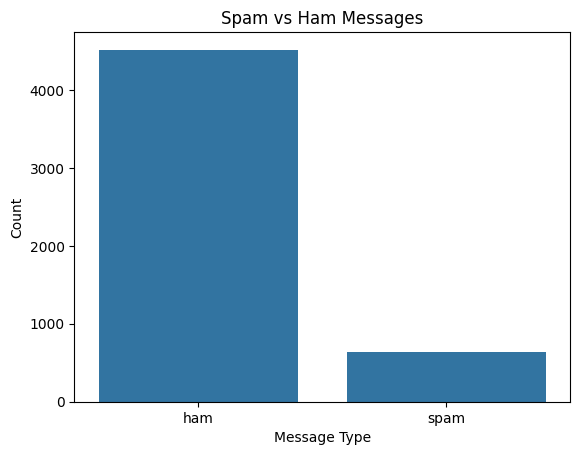

In [12]:
sns.countplot(data=df, x="Label")
plt.title("Spam vs Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Count")
plt.show()

Convert text labels into numbers

In [13]:
df["Target"] = df["Label"].map({
    "ham": 0,
    "spam": 1
})

print(df[["Message", "Label", "Target"]].head())

                                             Message Label  Target
0  Go until jurong point, crazy.. Available only ...   ham       0
1                      Ok lar... Joking wif u oni...   ham       0
2  Free entry in 2 a wkly comp to win FA Cup fina...  spam       1
3  U dun say so early hor... U c already then say...   ham       0
4  Nah I don't think he goes to usf, he lives aro...   ham       0


Split the dataset

In [14]:
from sklearn.model_selection import train_test_split

X = df["Message"]
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4126
Testing messages: 1032


Convert text using TF-IDF

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (4126, 7400)
Testing matrix: (1032, 7400)


Train the Machine Learning model

In [16]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


Evaluate the model

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test_tfidf)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
))

Accuracy: 0.9574
Precision: 0.9884
Recall: 0.6641
F1 Score: 0.7944

Classification Report:
              precision    recall  f1-score   support

         Ham       0.95      1.00      0.98       904
        Spam       0.99      0.66      0.79       128

    accuracy                           0.96      1032
   macro avg       0.97      0.83      0.89      1032
weighted avg       0.96      0.96      0.95      1032



Confusion Matrix

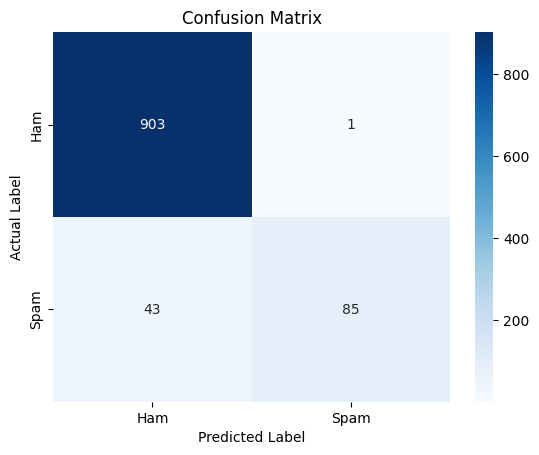

In [18]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

Test a new message

In [19]:
def predict_message(message):
    message_tfidf = tfidf.transform([message])
    prediction = model.predict(message_tfidf)[0]

    if prediction == 1:
        print("Prediction: SPAM")
    else:
        print("Prediction: HAM (Normal Message)")


predict_message("Congratulations! You won a free prize. Click now!")
predict_message("Hi, how are you? Shall we meet today?")
predict_message("Your bank account is blocked. Click this link now.")

Prediction: SPAM
Prediction: HAM (Normal Message)
Prediction: HAM (Normal Message)


Save the trained model

In [20]:
import joblib

joblib.dump(model, "spam_detection_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!
